<p style="text-align:center">
    <a href="https://www.ict.mahidol.ac.th/en/" target="_blank">
    <img src="https://www3.ict.mahidol.ac.th/ICTSurveysV2/Content/image/MUICT2.png" width="400" alt="Faculty of ICT">
    </a>
</p>

# ITGE275: Economics
## Session 10: The Central Bank’s Levers – Monetary Policy & Interest Rates

---
### 👦 Student Information 👧

**Your name:** Qimin Zhu  
**ID:** 6888143

---

### **1. Introduction: The Manager of the Economy**

In Session 9, we learned how the Government steers the economy through Fiscal Policy (Taxes and Spending). Today, we meet the other manager: **The Central Bank** (e.g., Bank of Thailand, US Federal Reserve).

The Central Bank controls **Monetary Policy**, primarily by managing the **Money Supply** and **Interest Rates**. 



**The Transmission Mechanism:**
1. Central Bank changes the **Policy Rate** (the rate banks charge each other).
2. Commercial Banks change their **Loan/Deposit Rates**.
3. Consumers and Firms alter their **Consumption and Investment**.
4. Aggregate Demand changes, impacting **Inflation and GDP Growth**.

In [1]:
# Step 1: Import Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display

# Configure plotting style
%matplotlib inline
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

print("Libraries loaded successfully.")

Libraries loaded successfully.


### **2. The Magic of Banking (Fractional Reserve)**

Commercial banks do not just hold money in vaults; they *create* money through **Fractional Reserve Banking**.



* You deposit \\$1,000.
* The bank holds 10% in reserve (\\$100) and loans out \\$900.
* That \\$900 is used to buy a laptop, and the electronics store deposits the \\$900 back into a bank.
* The bank holds 10% (\\$90) and loans out \$810.
* **Result:** The initial \\$1,000 deposit has expanded the money supply significantly.

Because money represents time and risk, borrowing it comes with a cost: **Interest**.

### **3. The Power of Interest Rates: Simple vs. Compound**

When Central Banks change interest rates, it profoundly affects long-term loans like mortgages. Let's visualize the difference between **Simple Interest** (rare) and **Compound Interest** (standard for loans/investments) over a 30-year period.

In [ ]:
def plot_interest_types(principal=1000000, rate_percent=5.0, years=30):
    rate = rate_percent / 100
    time_array = np.arange(0, years + 1)
    
    # Simple Interest Formula: A = P(1 + rt)
    simple_interest = principal * (1 + rate * time_array)
    
    # Compound Interest Formula: A = P(1 + r)^t
    compound_interest = principal * (1 + rate)**time_array
    
    fig, ax = plt.subplots(figsize=(10, 6))
    
    ax.plot(time_array, simple_interest, label='Simple Interest', color='blue', linewidth=2)
    ax.plot(time_array, compound_interest, label='Compound Interest', color='red', linewidth=2)
    ax.fill_between(time_array, simple_interest, compound_interest, color='red', alpha=0.1, label='The "Compound Gap"')
    
    ax.set_title(f'Growth of {principal:,.0f} THB over {years} Years at {rate_percent}%', fontsize=14)
    ax.set_xlabel('Years')
    ax.set_ylabel('Total Amount (Principal + Interest) [THB]')
    ax.legend()
    
    # Annotate final values
    ax.text(years, simple_interest[-1], f'  {simple_interest[-1]:,.0f}', verticalalignment='top')
    ax.text(years, compound_interest[-1], f'  {compound_interest[-1]:,.0f}', verticalalignment='bottom')
    
    plt.show()
    
    print(f"--- End of Year {years} ---")
    print(f"Total Paid (Simple):   {simple_interest[-1]:,.2f} THB")
    print(f"Total Paid (Compound): {compound_interest[-1]:,.2f} THB")

# Interactive Widget
widgets.interactive(plot_interest_types,
                    principal=widgets.IntSlider(min=500000, max=5000000, step=100000, value=2000000, description='Loan Amount'),
                    rate_percent=widgets.FloatSlider(min=1.0, max=15.0, step=0.5, value=5.0, description='Interest Rate (%)'),
                    years=widgets.IntSlider(min=5, max=40, step=1, value=30, description='Loan Term (Years)'))

interactive(children=(IntSlider(value=2000000, description='Loan Amount', max=5000000, min=500000, step=100000…

### **4. Case Study: The 2022-2024 Global Rate Hike**

In 2022, following post-COVID supply chain issues and geopolitical conflicts, global inflation skyrocketed. Central Banks panicked. Their response? **Aggressive Interest Rate Hikes.**



* **Goal:** Make borrowing expensive $\to$ Slow down consumption and corporate expansion $\to$ Cool down the economy $\to$ Lower Inflation.
* **Side Effect:** Tech stocks crashed (expensive to borrow for growth), and mortgage costs doubled, hurting homebuyers.

Let's visualize this relationship using synthetic macroeconomic data simulating the last 5 years.

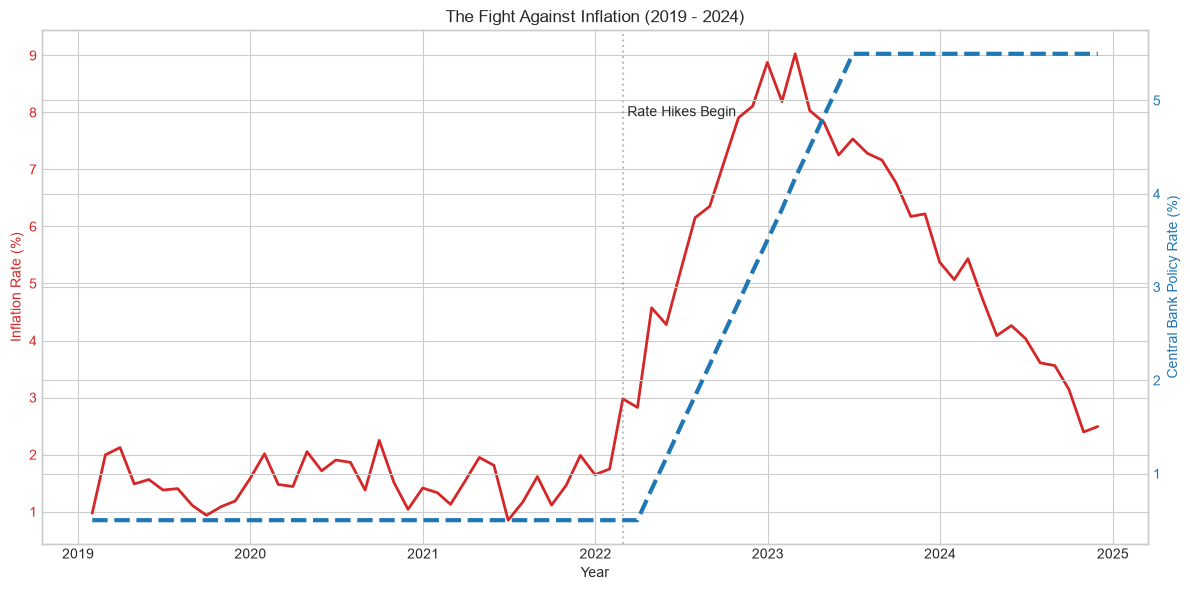

In [3]:
# Generate Synthetic Macro Data (Mimicking 2019-2024 Global Trends)
dates = pd.date_range(start='2019-01-01', end='2024-12-01', freq='ME')
n_months = len(dates)

# Simulate Inflation (Spikes in 2022, cools down in 2023-2024)
inflation = np.zeros(n_months)
inflation[:36] = np.random.normal(1.5, 0.3, 36)          # 2019-2021: Low/Stable
inflation[36:48] = np.linspace(2.0, 9.0, 12) + np.random.normal(0, 0.5, 12)  # 2022: Massive Spike
inflation[48:] = np.linspace(9.0, 2.5, n_months-48) + np.random.normal(0, 0.3, n_months-48) # 2023-24: Cooling

# Simulate Policy Rate (Follows inflation, but lags slightly)
policy_rate = np.zeros(n_months)
policy_rate[:38] = 0.5  # 2019 - early 2022: Near zero rates to stimulate COVID economy
policy_rate[38:54] = np.linspace(0.5, 5.5, 16) # Mid 2022 - Late 2023: Aggressive Hikes
policy_rate[54:] = 5.5  # 2024: Rates held "Higher for Longer"

df_macro = pd.DataFrame({'Date': dates, 'Inflation': inflation, 'Policy_Rate': policy_rate})
df_macro.set_index('Date', inplace=True)

# --- Visualization: Dual Axis Chart ---
fig, ax1 = plt.subplots(figsize=(12, 6))

color = 'tab:red'
ax1.set_xlabel('Year')
ax1.set_ylabel('Inflation Rate (%)', color=color)
ax1.plot(df_macro.index, df_macro['Inflation'], color=color, linewidth=2, label='Inflation')
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()  # instantiate a second axes that shares the same x-axis
color = 'tab:blue'
ax2.set_ylabel('Central Bank Policy Rate (%)', color=color)
ax2.plot(df_macro.index, df_macro['Policy_Rate'], color=color, linewidth=3, linestyle='--', label='Policy Rate')
ax2.tick_params(axis='y', labelcolor=color)

# Annotations
ax1.axvline(pd.to_datetime('2022-03-01'), color='gray', linestyle=':', alpha=0.5)
ax1.text(pd.to_datetime('2022-03-01'), 8, ' Rate Hikes Begin', verticalalignment='center')

plt.title('The Fight Against Inflation (2019 - 2024)')
fig.tight_layout()
plt.show()

### **5. Computational Approach: The Taylor Rule**

How does a Central Bank decide exactly *what* the interest rate should be? Many use an algorithm/heuristic known as the **Taylor Rule**.

$$ i = r^* + \pi + 0.5(\pi - \pi^*) + 0.5(y_{gap}) $$

Where:
* **$i$**: Target Nominal Interest Rate
* **$r^*$**: Natural Real Interest Rate (assumed ~2.0%)
* **$\pi$**: Current Inflation Rate
* **$\pi^*$**: Target Inflation Rate (usually 2.0%)
* **$y_{gap}$**: GDP Gap (Actual GDP - Potential GDP). If negative, we are in a recession.

**Logic:** If inflation is too high, or GDP is overheating, the formula dictates a HIGHER interest rate. If we are in a recession, it dictates a LOWER rate.

In [4]:
def calculate_taylor_rule(current_inflation, target_inflation, gdp_gap, actual_central_bank_rate):
    # Constant
    neutral_real_rate = 2.0 
    
    # Taylor Rule Formula
    taylor_rate = neutral_real_rate + current_inflation + 0.5 * (current_inflation - target_inflation) + 0.5 * gdp_gap
    
    # Determine Stance
    diff = actual_central_bank_rate - taylor_rate
    if diff > 0.5:
        stance = "TOO HAWKISH (Rates are higher than the rule suggests. Risking recession.)"
        color = 'red'
    elif diff < -0.5:
        stance = "TOO DOVISH (Rates are lower than the rule suggests. Risking inflation.)"
        color = 'blue'
    else:
        stance = "JUST RIGHT (In line with Taylor Rule recommendations.)"
        color = 'green'

    # Visualization
    fig, ax = plt.subplots(figsize=(10, 4))
    
    y_pos = ['Actual Central Bank Rate', 'Taylor Rule Recommended Rate']
    rates = [actual_central_bank_rate, taylor_rate]
    
    bars = ax.barh(y_pos, rates, color=['gray', color])
    ax.set_xlim(0, max(10, max(rates) + 2))
    ax.set_xlabel('Interest Rate (%)')
    ax.set_title('Central Bank Policy Evaluation')
    
    # Add labels to bars
    for bar in bars:
        width = bar.get_width()
        ax.text(width + 0.2, bar.get_y() + bar.get_height()/2, f'{width:.2f}%', va='center')

    plt.show()
    
    print(f"--- ANALYSIS ---")
    print(f"Current Inflation: {current_inflation}% | Target: {target_inflation}%")
    print(f"GDP Gap: {gdp_gap}% (Negative means recession)")
    print(f"\nVerdict: {stance}")

style = {'description_width': 'initial'}
widgets.interactive(calculate_taylor_rule,
                    current_inflation=widgets.FloatSlider(min=-2.0, max=10.0, step=0.5, value=4.0, description='Current Inflation (%)', style=style),
                    target_inflation=widgets.FloatSlider(min=1.0, max=4.0, step=0.5, value=2.0, description='Target Inflation (%)', style=style),
                    gdp_gap=widgets.FloatSlider(min=-5.0, max=5.0, step=0.5, value=-1.0, description='GDP Gap (%)', style=style),
                    actual_central_bank_rate=widgets.FloatSlider(min=0.0, max=10.0, step=0.25, value=5.5, description='Actual Bank Rate (%)', style=style))

interactive(children=(FloatSlider(value=4.0, description='Current Inflation (%)', max=10.0, min=-2.0, step=0.5…

---
## **6. Homework Assignment**

**Objective:** Apply monetary policy theory and analyze the Taylor Rule output.

#### **Question 1: Evaluating the Central Bank**
Imagine the following economic scenario for a country:
* **Current Inflation:** 6.0% (High)
* **Target Inflation:** 2.0%
* **GDP Gap:** +2.0% (The economy is booming/overheating)
* **Actual Central Bank Rate:** 3.5%

1. Input these values into the Taylor Rule simulator in Section 5.
2. What is the "Taylor Rule Recommended Rate"?
3. Is the Central Bank currently "Too Hawkish" or "Too Dovish"? What risk is the country facing because of this policy stance?

#### **Question 2: The Ultimate Trade-off**
During 2022-2023, Central Banks aggressively raised interest rates. 
Explain, in your own words using the **Transmission Mechanism**, how raising the Policy Rate helps reduce Inflation, but why doing so might trigger an economic Recession (slowing down GDP Growth).

*(Write your answers in the Markdown cell below)*

### **Student Answers Space**

**Q1 Analysis:**

Taylor Rule Recommand Rate: 11%.

Central Bank Currently Too Dovish. 

Persisten inflation, and currancy depreciation.

**Q2 Analysis:**

Raising interest rate will affect the loan borrowing rate, less people loan to invest, then demand decrease. After all of that, the GDP growth will slow down due to less money flowing in the market.